# Lecture 7 — Class Exercise
## Part-to-Whole: Hierarchical Visualization

> **Push to:** `week07/lecture07_exercise.ipynb`


In [1]:
import plotly.io as pio
pio.renderers.default = 'plotly_mimetype+notebook_connected+png'

import pandas as pd
import plotly.express as px
import numpy as np

# Dataset: Global Energy Mix by Country and Source
df = pd.read_csv('../data/global_energy_mix.csv')

# Source type mapping — reuse from lecture
source_category = {
    'Coal': 'Fossil', 'Oil': 'Fossil', 'Natural Gas': 'Fossil',
    'Nuclear': 'Low-carbon', 'Hydro': 'Low-carbon',
    'Wind': 'Renewable', 'Solar': 'Renewable', 'Other Renewables': 'Renewable'
}
df['Source_Type'] = df['Source'].map(source_category)

print(f"Loaded: {len(df)} rows")
print(df.head(10))


Loaded: 103 rows
         Country         Region            Source  Share_pct     TWh  \
0  United States  North America              Coal         10  1015.0   
1  United States  North America               Oil         35  3220.0   
2  United States  North America       Natural Gas         34  3083.0   
3  United States  North America           Nuclear          9   798.0   
4  United States  North America             Hydro          3   339.0   
5  United States  North America              Wind          4   413.0   
6  United States  North America             Solar          3   325.0   
7  United States  North America  Other Renewables          2   229.0   
8          China           Asia              Coal         58  6929.1   
9          China           Asia               Oil         18  1620.0   

  Source_Type  
0      Fossil  
1      Fossil  
2      Fossil  
3  Low-carbon  
4  Low-carbon  
5   Renewable  
6   Renewable  
7   Renewable  
8      Fossil  
9      Fossil  


## Task 1 — Treemap: fossil fuel dependency by country

**What to build:** A treemap showing **fossil fuel TWh only**, broken down by Region → Country → Source (Coal / Oil / Natural Gas).

**Requirements:**
- Filter to fossil sources only before plotting
- Use `path=['Region', 'Country', 'Source']` for the hierarchy
- Colour encodes the fossil source type (Coal / Oil / Natural Gas) with a CVD-safe palette
- Show TWh values in labels — no percentages
- Grey out parent nodes (Region and Country level)
- Insight title naming which region or country is most fossil-dependent

> 💡 `df.loc[df['Source_Type'] == 'Fossil']`


Fossil total: 100,372 TWh
Region
Asia             0.349
Europe           0.153
Latin America    0.123
North America    0.111
Middle East      0.096
Africa           0.086
Oceania          0.081
Country
Saudi Arabia    9671.0
Japan           9442.0
China           9421.1
South Africa    8620.0
South Korea     8252.0


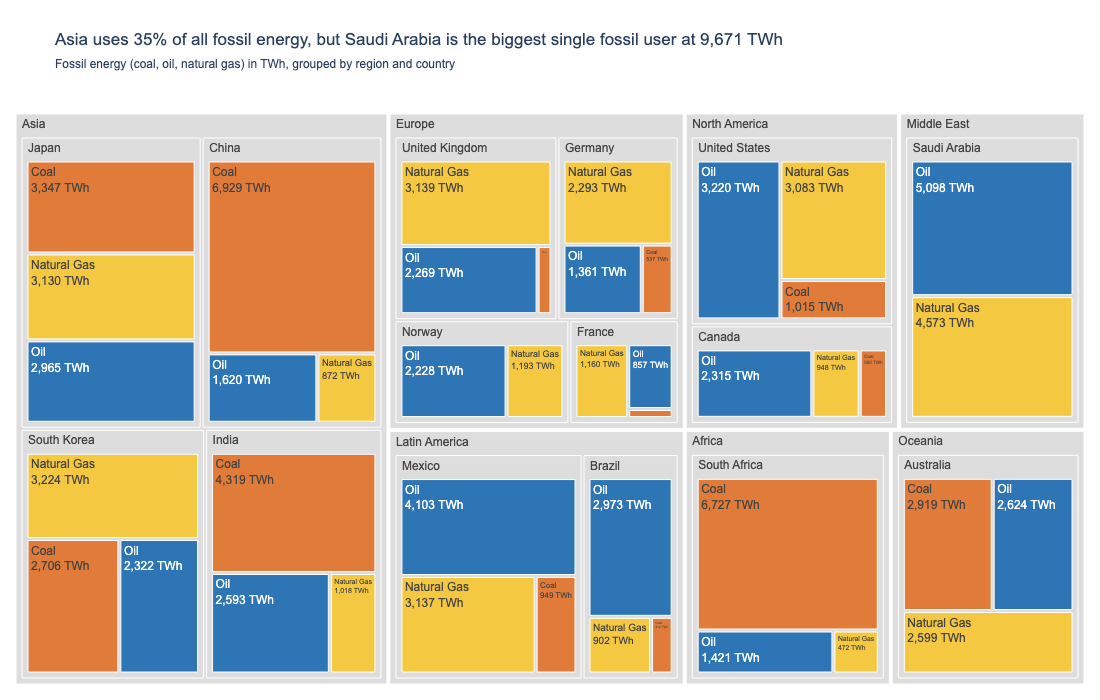

In [2]:
df_fossil = df.loc[df['Source_Type'] == 'Fossil'].copy()

fossil_total = df_fossil['TWh'].sum()
by_region = df_fossil.groupby('Region')['TWh'].sum().sort_values(ascending=False)
by_country = df_fossil.groupby('Country')['TWh'].sum().sort_values(ascending=False)
print(f"Fossil total: {fossil_total:,.0f} TWh")
print((by_region / fossil_total).round(3).to_string())
print(by_country.head(5).to_string())

top_region, top_region_share = by_region.index[0], by_region.iloc[0] / fossil_total
top_country, top_country_twh = by_country.index[0], by_country.iloc[0]

fossil_colors = {
    'Coal':        '#E07B39',
    'Oil':         '#2E75B6',
    'Natural Gas': '#F5C842',
}

fig = px.treemap(
    data_frame=df_fossil,
    path=['Region', 'Country', 'Source'],
    values='TWh',
    color='Source',
    color_discrete_map=fossil_colors,
    height=700, width=1100,
    template='plotly_white'
)

fig.update_traces(
    texttemplate='%{label}<br>%{value:,.0f} TWh',
    hovertemplate='<b>%{label}</b><br>%{value:,.0f} TWh<extra></extra>'
)

fig.update_layout(
    title=dict(
        text=f"{top_region} uses {top_region_share:.0%} of all fossil energy, but {top_country} "
             f"is the biggest single fossil user at {top_country_twh:,.0f} TWh",
        subtitle=dict(text='Fossil energy (coal, oil, natural gas) in TWh, grouped by region and country')
    ),
    font=dict(family='Arial', size=12),
    margin=dict(t=90, l=10, r=10, b=10)
)

fig.data[0].marker.colors = [
    c if c in fossil_colors.values() else '#DDDDDD'
    for c in fig.data[0].marker.colors
]

fig.show()

## Task 2 — Treemap vs bar: low-carbon energy by country

**What to build:** Build **both** a treemap and a horizontal bar chart showing total low-carbon TWh (Nuclear + Hydro) per country. Then answer the question in a markdown cell below.

**Requirements:**
- Filter to `Source_Type == 'Low-carbon'` and aggregate TWh by country
- Treemap: single-level `path=['All', 'Country']` with a dummy root node labelled `'Low-carbon'`
- Bar chart: sorted by TWh, horizontal orientation, CVD-safe colour
- Both charts show TWh values, not percentages
- Insight title on the bar chart naming the leading country

       Country    TWh
        France 7593.0
        Norway 6174.0
        Canada 5969.0
        Brazil 4975.0
   South Korea 2484.0
         India 1336.0
 United States 1137.0
         Japan 1012.0
United Kingdom  993.0
       Germany  929.0
        Mexico  906.0
         China  882.0
  South Africa  726.0
     Australia  448.0
France leads Norway by 23%; top 4 hold 69%; not in data: ['Saudi Arabia']


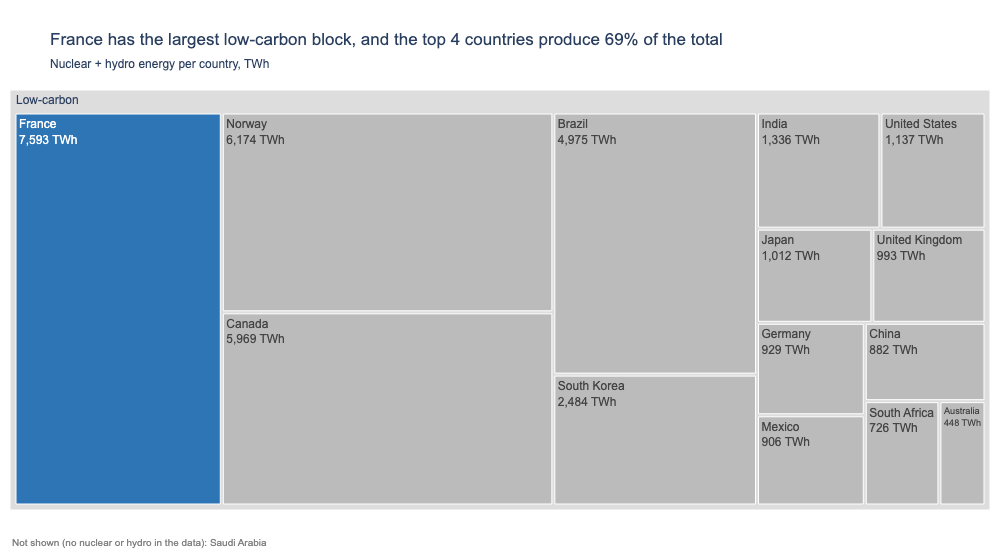

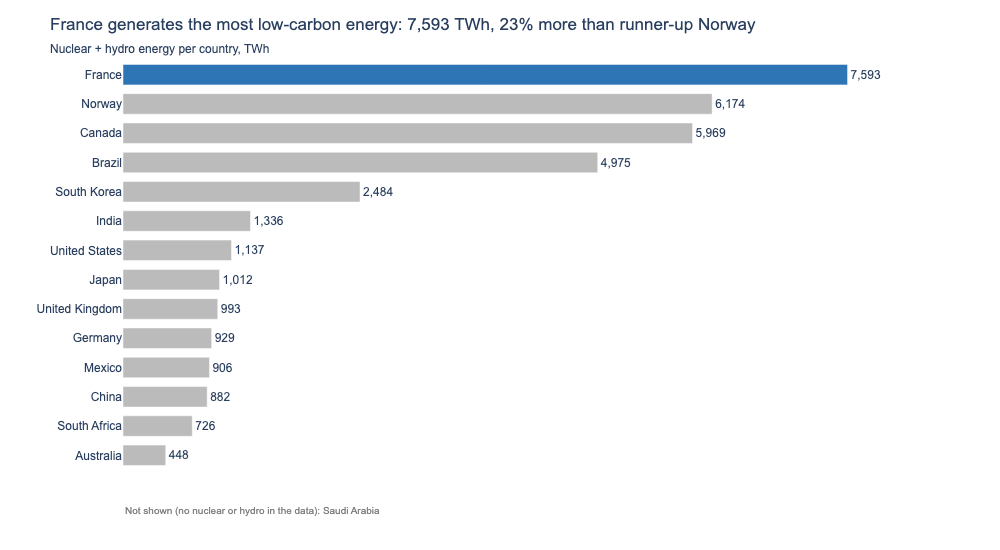

In [3]:
df_lc = (df.loc[df['Source_Type'] == 'Low-carbon']
           .groupby('Country', as_index=False)['TWh'].sum()
           .sort_values('TWh', ascending=False))
df_lc['All'] = 'Low-carbon'

leader, runner_up = df_lc['Country'].iloc[0], df_lc['Country'].iloc[1]
leader_twh, runner_up_twh = df_lc['TWh'].iloc[0], df_lc['TWh'].iloc[1]
lead_pct = leader_twh / runner_up_twh - 1
top4_share = df_lc['TWh'].head(4).sum() / df_lc['TWh'].sum()
missing = sorted(set(df['Country']) - set(df_lc['Country']))
print(df_lc[['Country', 'TWh']].to_string(index=False))
print(f"{leader} leads {runner_up} by {lead_pct:.0%}; top 4 hold {top4_share:.0%}; not in data: {missing}")

ACCENT, CONTEXT = '#2E75B6', '#BBBBBB'
df_lc['Highlight'] = np.where(df_lc['Country'] == leader, 'Leader', 'Other')
highlight_colors = {'Leader': ACCENT, 'Other': CONTEXT}
footnote = f"Not shown (no nuclear or hydro in the data): {', '.join(missing)}"

fig = px.treemap(
    data_frame=df_lc,
    path=['All', 'Country'],
    values='TWh',
    color='Highlight',
    color_discrete_map=highlight_colors,
    height=550, width=1000,
    template='plotly_white'
)

fig.update_traces(
    texttemplate='%{label}<br>%{value:,.0f} TWh',
    hovertemplate='<b>%{label}</b><br>%{value:,.0f} TWh<extra></extra>'
)

fig.update_layout(
    title=dict(
        text=f"{leader} has the largest low-carbon block, and the top 4 countries "
             f"produce {top4_share:.0%} of the total",
        subtitle=dict(text='Nuclear + hydro energy per country, TWh')
    ),
    font=dict(family='Arial', size=12),
    margin=dict(t=90, l=10, r=10, b=40)
)

fig.data[0].marker.colors = [
    c if c in highlight_colors.values() else '#DDDDDD'
    for c in fig.data[0].marker.colors
]

fig.add_annotation(
    xref='paper', yref='paper', x=0, y=-0.06,
    xanchor='left', yanchor='top',
    text=footnote, showarrow=False,
    font=dict(size=10, color='grey')
)

fig.show()

fig = px.bar(
    data_frame=df_lc,
    x='TWh', y='Country',
    orientation='h',
    color='Highlight',
    color_discrete_map=highlight_colors,
    text='TWh',
    category_orders={'Country': df_lc['Country'].tolist()},
    labels={'TWh': 'Low-carbon energy (TWh)', 'Country': ''},
    hover_data={'Highlight': False},
    height=550, width=1000,
    template='plotly_white'
)

fig.update_traces(
    texttemplate='%{x:,.0f}',
    textposition='outside',
    cliponaxis=False
)

fig.update_layout(
    title=dict(
        text=f"{leader} generates the most low-carbon energy: {leader_twh:,.0f} TWh, "
             f"{lead_pct:.0%} more than runner-up {runner_up}",
        subtitle=dict(text='Nuclear + hydro energy per country, TWh')
    ),
    font=dict(family='Arial', size=12),
    showlegend=False,
    bargap=0.3,
    xaxis=dict(visible=False, range=[0, leader_twh * 1.1]),
    yaxis=dict(title='')
)

fig.add_annotation(
    xref='paper', yref='paper', x=0, y=-0.08,
    xanchor='left', yanchor='top',
    text=footnote, showarrow=False,
    font=dict(size=10, color='grey')
)

fig.show()

### Task 2 — reflection

**Which chart tells the ranking story more clearly, and why?**

**The horizontal bar chart.** Every bar starts at the same zero baseline, so the eye compares lengths, which is the most accurate visual judgement we make. The bars are sorted and labelled, so the ranking reads straight from top to bottom: France (7,593 TWh), Norway (6,174), Canada (5,969), Brazil (4,975).

In the treemap the same numbers become rectangles of different shapes, and area is much harder to compare than length. Norway and Canada differ by only about 3%, and without reading the labels it is impossible to tell which block is bigger.

The treemap is better at a different question, part-to-whole: it shows at a glance that the top four countries hold about 69% of all low-carbon energy.

## Task 3 — 100% stacked bar: which region relies most on coal?

**What to build:** A horizontal 100% stacked bar chart showing, for each **Region**, how its fossil energy splits between Coal, Oil and Natural Gas. This is the **same data as your Task 1 treemap**, visualised a second way.

**Requirements:**
- Reuse `df_fossil` from Task 1; aggregate TWh by `Region` × `Source` and convert to **shares of each region's fossil total**
- Horizontal bars, regions **sorted by coal share** (highest at the top)
- Coal is the segment on the baseline (first in `category_orders`) and the **only coloured segment** — keep it the same colour as in Task 1; Oil and Natural Gas in two greys
- Percentage labels on the coal segments only
- Insight title naming the most coal-dependent region and its coal share

> 💡 `df.groupby('Region')['TWh'].transform('sum')` gives each row its region total

       Region  Share
       Africa  0.780
         Asia  0.494
      Oceania  0.359
North America  0.141
Latin America  0.102
       Europe  0.058
  Middle East  0.000


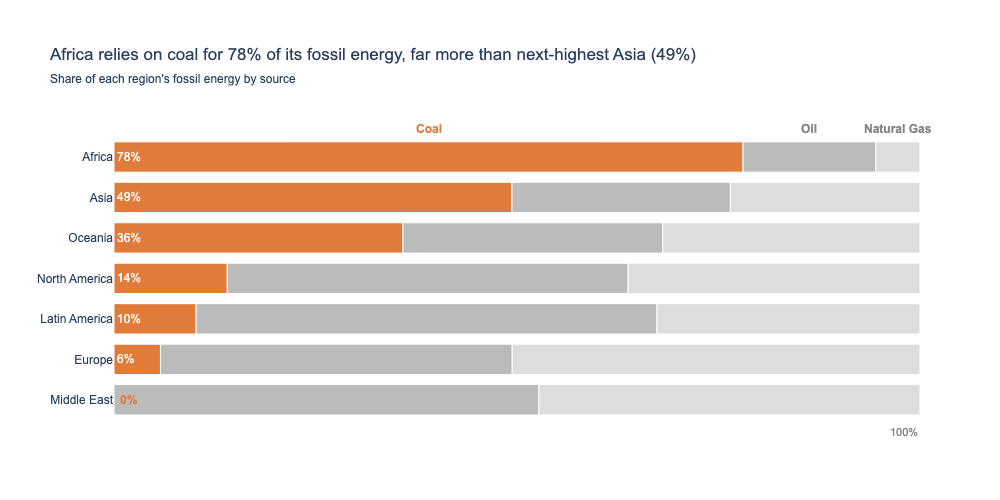

In [4]:
fossil_mix = (df_fossil.groupby(['Region', 'Source'])['TWh'].sum()
                .unstack(fill_value=0)
                .stack()
                .reset_index(name='TWh'))
fossil_mix['Share'] = fossil_mix['TWh'] / fossil_mix.groupby('Region')['TWh'].transform('sum')

coal = fossil_mix.loc[fossil_mix['Source'] == 'Coal'].sort_values('Share', ascending=False)
region_order = coal['Region'].tolist()
top_region, top_share = coal['Region'].iloc[0], coal['Share'].iloc[0]
next_region, next_share = coal['Region'].iloc[1], coal['Share'].iloc[1]
print(coal[['Region', 'Share']].round(3).to_string(index=False))

fossil_mix['Label'] = np.where(
    (fossil_mix['Source'] == 'Coal') & (fossil_mix['Share'] > 0),
    fossil_mix['Share'].map('{:.0%}'.format), ''
)

source_order = ['Coal', 'Oil', 'Natural Gas']
accent_colors = {
    'Coal':        fossil_colors['Coal'],
    'Oil':         '#BBBBBB',
    'Natural Gas': '#DDDDDD',
}

fig = px.bar(
    data_frame=fossil_mix,
    x='Share', y='Region',
    orientation='h',
    color='Source',
    text='Label',
    color_discrete_map=accent_colors,
    category_orders={'Region': region_order, 'Source': source_order},
    labels={'Share': 'Share of fossil energy', 'Region': ''},
    hover_data={'Label': False, 'Share': ':.1%', 'TWh': ':,.0f'},
    height=500, width=1000,
    template='plotly_white'
)

fig.update_traces(
    textposition='inside', insidetextanchor='start',
    textfont=dict(color='white', size=12),
    marker_line_color='white', marker_line_width=1
)

fig.update_layout(
    title=dict(
        text=f"{top_region} relies on coal for {top_share:.0%} of its fossil energy, "
             f"far more than next-highest {next_region} ({next_share:.0%})",
        subtitle=dict(text="Share of each region's fossil energy by source")
    ),
    font=dict(family='Arial', size=12),
    showlegend=False,
    bargap=0.25,
    xaxis=dict(visible=False, range=[0, 1]),
    yaxis=dict(title=''),
    margin=dict(t=120)
)

top_bar = (fossil_mix.loc[fossil_mix['Region'] == top_region]
             .set_index('Source')['Share'].reindex(source_order))
left = 0
for source, share in top_bar.items():
    fig.add_annotation(
        x=left + share / 2, y=top_region,
        xref='x', yref='y', yshift=28,
        text=f'<b>{source}</b>', showarrow=False,
        font=dict(size=12, color=accent_colors['Coal'] if source == 'Coal' else '#888888')
    )
    left += share

for region in coal.loc[coal['Share'] == 0, 'Region']:
    fig.add_annotation(
        x=0, y=region, xref='x', yref='y',
        xanchor='left', xshift=4,
        text='<b>0%</b>', showarrow=False,
        font=dict(size=12, color=accent_colors['Coal'])
    )

fig.add_annotation(
    x=1, y=0, xref='x', yref='paper',
    xanchor='right', yanchor='top', yshift=-4,
    text='100%', showarrow=False,
    font=dict(size=11, color='grey')
)

fig.show()

### Task 3 — reflection

**Your Task 1 treemap and this stacked bar show the same fossil data. Name one question each chart answers that the other cannot.**

- **Only the treemap:** *How much fossil energy does each region and country use in absolute terms?* Asia is by far the largest block (about 35% of all fossil TWh), and Saudi Arabia is the biggest single country. The stacked bar scales every region to 100%, so absolute size disappears: Oceania (one country) and Asia (four countries) get bars of the same length.
- **Only the stacked bar:** *Which region depends most on coal, and how do the regions rank by coal share?* Africa (78%) is far ahead of Asia (49%), and every bar shares the same 0–100% scale, so the shares compare directly. In the treemap the coal blocks sit inside parent rectangles of different sizes and shapes, so you cannot compare coal's share across regions by area.